# Solutions to the exercises of Chapter 14

Sample solutions for [Chapter 14, Molecular diffusion](../../notebooks/part4_mass_transfer/14_molecular_diffusion.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

try:
    from engtransport import diffusion, properties
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import diffusion, properties
from engtransport.plotting import use_style

use_style()
R_GAS, P_ATM, T25 = 8.314462618, 101325.0, 298.15
c25 = P_ATM / (R_GAS * T25)

## Exercise 1. Methanol in a Stefan tube

In [2]:
def tube(name, formula, T):
    c = P_ATM / (R_GAS * T)
    s = properties.solvent_saturation(name, T)
    x_s = s["p_sat"] / P_ATM
    r = s["rho_l"] / s["M"] / c
    D = properties.fuller_diffusivity(formula, "Air", T)
    return x_s, r, D, 2 * D / r * math.log(1 / (1 - x_s))


for name, formula in (("methanol", "CH3OH"), ("ethanol", "C2H5OH")):
    x_s, r, D, K = tube(name, formula, T25)
    print(f"{name:8s} at 25 C: x_s = {x_s:.4f}, r = {r:.0f}, D = {D * 1e6:.2f} mm2/s; 10 -> 20 mm in {(0.02**2 - 0.01**2) / K / 3600:.1f} h")
x_s, r, D, K = tube("methanol", "CH3OH", T25)
x_hot = properties.solvent_saturation("methanol", T25 + 0.5)["p_sat"] / P_ATM
print(f"a bath 0.5 K warmer: ln-term larger by {100 * (math.log(1 - x_hot) / math.log(1 - x_s) - 1):.1f} %,"
      f" so the measured D is {100 * (math.log(1 - x_hot) / math.log(1 - x_s) - 1):.1f} % too high")

methanol at 25 C: x_s = 0.1676, r = 600, D = 16.02 mm2/s; 10 -> 20 mm in 8.5 h
ethanol  at 25 C: x_s = 0.0778, r = 417, D = 12.28 mm2/s; 10 -> 20 mm in 17.5 h
a bath 0.5 K warmer: ln-term larger by 2.9 %, so the measured D is 2.9 % too high


Methanol has twice the vapour pressure of ethanol and a 30 % larger diffusivity, but a
44 % larger molar density ratio (its molecules are smaller, so a litre holds more of them),
and its level falls 10 mm in 8.5 hours instead of 17.5. A drift of 0.5 K raises the
logarithmic driving force by 2.9 %, and the diffusivity inferred from Eq. (14.8) is too
high by the same amount: to measure a diffusivity to 1 %, the temperature must be known to
about 0.17 K.

## Exercise 2. A catalytic surface

In [3]:
c, D, L, x_out = 40.0, 2e-5, 1e-3, 0.5
for label, sigma in (("A -> 2B (sigma = -1)", -1.0), ("equimolar, Fick (sigma = 0)", 0.0), ("B stagnant, Stefan (sigma = 1)", 1.0)):
    print(f"{label:32s}: N_A = {diffusion.film_flux(c, D, L, x_out, 0.0, sigma):.4f} mol/(m2 s)")
zeta = np.linspace(0, 1, 6)
print("profile for A -> 2B:", " ".join(f"{x:.3f}" for x in diffusion.film_profile(zeta, x_out, 0.0, sigma=-1.0)))

A -> 2B (sigma = -1)            : N_A = 0.3244 mol/(m2 s)
equimolar, Fick (sigma = 0)     : N_A = 0.4000 mol/(m2 s)
B stagnant, Stefan (sigma = 1)  : N_A = 0.5545 mol/(m2 s)
profile for A -> 2B: 0.500 0.383 0.275 0.176 0.084 -0.000


With $\sigma = -1$, Eq. (14.4) gives $N_A = (cD/L)\ln(1 + x_1) = 0.324$ mol/(m² s), against
0.400 from Fick's law and 0.555 for a stagnant gas. Each A that reaches the surface sends
two molecules of B back, so the mixture as a whole flows away from the catalyst, and the
drift carries A backwards. A reaction that produces more moles than it consumes slows its
own supply; one that consumes moles, A + B → C for instance, is helped by the drift.

## Exercise 3. A dust mulch

The vapour leaving the front at depth $s$ crosses the loose layer of thickness $d$ and
the dry loam below it, in series:
$N = c\ln[(1 - x_{top})/(1 - x_s)]\big/[d/D_1 + (s - d)/D_2]$, with $D_1$ and $D_2$ the
effective diffusivities (14.9) of the loose layer and of the loam, and the front moves as
$c_L\,ds/dt = N$.

after 10 days: loosened  12.8 mm (10 mm from the loose layer itself); untilled   7.1 mm
after 30 days: loosened  16.8 mm (10 mm from the loose layer itself); untilled  12.3 mm
after 90 days: loosened  24.9 mm (10 mm from the loose layer itself); untilled  21.2 mm
effective diffusivities: loose layer 11.50, loam 8.80 mm2/s


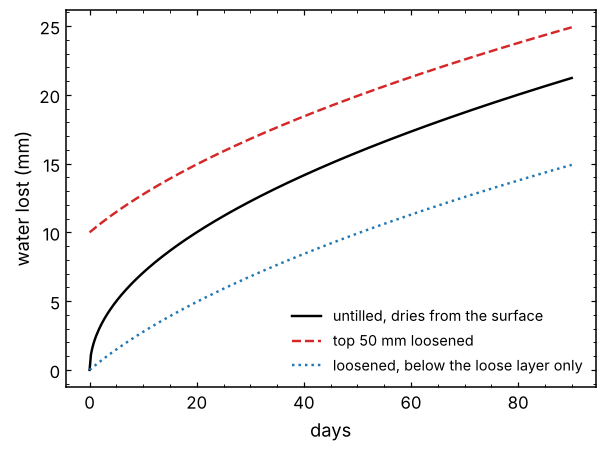

In [4]:
p_w = properties.saturated_water(T25)["p_sat"]
D_w = properties.water_vapour_diffusivity_air(T25)
x_s, x_top = p_w / P_ATM, 0.3 * p_w / P_ATM
D_loam, D_loose = D_w * diffusion.millington_quirk(0.45), D_w * diffusion.millington_quirk(0.55)
theta, d = 0.20, 0.050
c_L = 1000.0 * theta / 0.018015
drive = c25 * math.log((1 - x_top) / (1 - x_s))

days = np.linspace(0, 90, 361)
front = solve_ivp(lambda t, u: [drive / (d / D_loose + u[0] / D_loam) / c_L], [0, days[-1] * 86400], [0.0],
                  t_eval=days * 86400, rtol=1e-10, atol=1e-14).y[0]
loss_mulch = 1e3 * theta * (d + front)          # the water of the loosened layer is lost as well
loss_plain = 1e3 * theta * diffusion.stefan_tube_level(days * 86400, 0.0, D_loam, x_s, x_top, c_L / c25)
for day in (10, 30, 90):
    i = np.searchsorted(days, day)
    print(f"after {day:2d} days: loosened {loss_mulch[i]:5.1f} mm ({1e3 * theta * d:.0f} mm from the loose layer itself);"
          f" untilled {loss_plain[i]:5.1f} mm")
print(f"effective diffusivities: loose layer {D_loose * 1e6:.2f}, loam {D_loam * 1e6:.2f} mm2/s")
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(days, loss_plain, "k-", label="untilled, dries from the surface")
ax.plot(days, loss_mulch, "C3--", label="top 50 mm loosened")
ax.plot(days, loss_mulch - 1e3 * theta * d, "C0:", label="loosened, below the loose layer only")
ax.set_xlabel("days")
ax.set_ylabel("water lost (mm)")
ax.legend(loc="lower right")
plt.show()

**Figure S14.1.** Water lost from the loam of Section 14.5 in air at 30 % humidity, with
and without a loosened top layer, in the diffusion model of the chapter.

Below the loose layer the front moves more slowly, and in 30 days only 6.8 mm leave from
there, against 12.3 mm from untilled soil. But the loose layer gave up its own 10 mm, so
the field as a whole loses 16.8 mm, more than without tilling, and stays behind even after
90 days. The loose soil is more porous, so in this model it passes vapour more easily than
the dense dry soil it replaces. A dust mulch can therefore not save water by slowing
vapour diffusion. Where it helps, it must do so by cutting short the first stage of
drying, when capillary flow feeds a wet surface at the full evaporation rate of open
water, and that stage is not in this model. The calculation shows which part of the
physics a practice must work through, and it is a reminder that a model answers only the
questions it contains.

## Exercise 4. Vapour in the wall of Chapter 2

Each layer of thickness $d$ resists vapour like a still air layer $\mu d$ thick; with the
vapour permeability of air $\delta_a = DM_w/RT$, its resistance is $\mu d/\delta_a$, and the
vapour flux is the difference of partial pressures over the sum of resistances, as in
Chapter 2 for heat. Where the vapour pressure would exceed the saturation pressure, vapour
condenses (or freezes), the pressure there is pinned at saturation, and the flux in exceeds
the flux out (the Glaser method of ISO 13788).

In [5]:
layers = (("plaster", 0.020, 0.8, 10), ("brick", 0.380, 0.7, 10), ("wool", 0.150, 0.04, 1), ("render", 0.010, 0.8, 25))
T_in, T_out, h_in, h_out = 293.15, 238.15, 8.0, 23.0
R_th = [1 / h_in] + [d / k for _, d, k, _ in layers] + [1 / h_out]
q = (T_in - T_out) / sum(R_th)
T_face = np.array([T_in - q * sum(R_th[:i + 1]) for i in range(len(layers) + 1)])   # the 5 interfaces


def p_sat(T):
    return properties.saturation_pressure_water(T) if T >= 273.15 else properties.saturation_pressure_ice(T)


p_in, p_out = 0.5 * p_sat(T_in), 0.85 * p_sat(T_out)
delta = lambda T: properties.water_vapour_diffusivity_air(T) * 0.018015 / (R_GAS * T)


def glaser(sd_barrier):
    """Interfaces from the room side; a barrier of the given mu*d sits between brick and wool."""
    T_nodes = [T_face[0], T_face[1], T_face[2], T_face[2], T_face[3], T_face[4]]
    Z = [mu * d / delta(0.5 * (T_face[i] + T_face[i + 1])) for i, (_, d, _, mu) in enumerate(layers)]
    Z.insert(2, sd_barrier / delta(T_face[2]))
    cum = np.concatenate([[0.0], np.cumsum(Z)])
    ps = np.array([p_sat(T) for T in T_nodes])
    p = p_in - (p_in - p_out) * cum / cum[-1]
    if np.all(p <= ps):
        return p, ps, 0.0
    k = int(np.argmax(p - ps))                     # condensation plane: the largest excess
    g_in = (p_in - ps[k]) / cum[k]
    g_out = (ps[k] - p_out) / (cum[-1] - cum[k])
    return p, ps, (g_in - g_out) * 86400 * 1e3, k


print("interface temperatures (C):", " ".join(f"{T - 273.15:.1f}" for T in T_face))
print(f"vapour pressure in the room {p_in:.0f} Pa, outside {p_out:.1f} Pa")
labels = ["room side", "plaster/brick", "brick/wool", "", "wool/render", "outside face"]
for sd in (0.0, 20.0):
    out = glaser(sd)
    p, ps, rate = out[:3]
    where = f" at the {labels[out[3]]} interface" if rate > 0 else ""
    print(f"barrier mu d = {sd:4.1f} m: p (Pa) " + " ".join(f"{v:.0f}" for v in p) + "; p_sat " + " ".join(f"{v:.0f}" for v in ps)
          + f"; condensation {rate:.2f} g/(m2 day){where}")
print(f"over 120 days of such weather: {glaser(0.0)[2] * 120 / 1e3:.2f} kg/m2 without a barrier, {glaser(20.0)[2] * 120 / 1e3:.2f} kg/m2 with it")

interface temperatures (C): 18.5 18.2 11.5 -34.3 -34.5
vapour pressure in the room 1167 Pa, outside 19.0 Pa
barrier mu d =  0.0 m: p (Pa) 1167 1116 136 136 94 19; p_sat 2122 2081 1357 1357 24 24; condensation 4.01 g/(m2 day) at the wool/render interface
barrier mu d = 20.0 m: p (Pa) 1167 1157 980 40 33 19; p_sat 2122 2081 1357 1357 24 24; condensation 0.46 g/(m2 day) at the wool/render interface
over 120 days of such weather: 0.48 kg/m2 without a barrier, 0.06 kg/m2 with it


Almost all of the temperature drop is across the wool, and almost all of the vapour
resistance is in the brick on the warm side. The linear vapour pressure at the cold face
of the wool, 94 Pa, is four times the saturation pressure over ice at −34.3 °C, 24 Pa, so
vapour freezes there, behind the render. About 4.0 g/(m² day) more arrives at that plane
than leaves it, close to half a kilogram per square metre over a winter of 120 such days.
A vapour barrier on the warm side of the wool with $\mu d = 20$ m cuts this to
0.46 g/(m² day), but does not stop it, because the render on
the cold side still resists vapour more than the wool does. The usual rule follows: the
layers should become more open to vapour towards the cold side, so a vapour-tight render
on external insulation needs a barrier on its warm side, or better a vapour-open render.
The Glaser method is a steady, worst-case estimate; real walls store moisture and dry
out in spring, and ISO 13788 judges them by the balance over a whole year.